# Understanding MDP in Reinforcement Learning

## Topic
**Markov Decision Process (MDP)** in Reinforcement Learning

## Lab Goal
In this lab, students will understand how an agent makes decisions in an environment using the concept of **states, actions, rewards, transitions, and discount factor**.

---

## Learning Objectives
By the end of this lab, students should be able to:

1. Understand what an MDP is.
2. Identify the main components of an MDP.
3. Explain MDP using a simple Grid World example.
4. Implement a small Grid World MDP in Python.
5. Apply **Value Iteration** to compute state values.
6. Extract a simple policy from the value function.

# 1. Introduction to MDP

**MDP** stands for **Markov Decision Process**.

It is a mathematical framework used in **Reinforcement Learning** to describe how an agent makes decisions in an environment.

In simple words:

> An agent observes the current situation, takes an action, receives a reward, and moves to a new situation.

### Real-life Example
Imagine a robot inside a room.

The robot can move:

- Left
- Right
- Up
- Down

After each move, it receives feedback:

- Good move: positive reward
- Bad move: negative reward
- Goal reached: high positive reward

The robot's aim is to learn which actions are best.

# 2. Main Components of MDP

An MDP is usually written as:

$$
MDP = (S, A, P, R, \gamma)
$$

Where:

| Component | Meaning |
|---|---|
| **S** | Set of states |
| **A** | Set of actions |
| **P** | Transition probability |
| **R** | Reward function |
| **γ** | Discount factor |

## 2.1 States

A **state** represents the current situation or position of the agent.

### Example
In a grid world, each cell can be considered a state.

For example:

- Robot at `(0,0)`
- Robot at `(0,1)`
- Robot at `(1,2)`

Each position is a different state.

## 2.2 Actions

An **action** is what the agent can do in a state.

### Example
In a grid world, possible actions are:

- Up
- Down
- Left
- Right

## 2.3 Transition Probability

Transition probability tells us the probability of moving from one state to another after taking an action.

### Example
If the robot chooses **Right**, it may:

- Move right with 80% probability
- Move up with 10% probability
- Move down with 10% probability

In this lab, we will use a simple deterministic environment where the robot moves exactly in the chosen direction if the move is valid.

## 2.4 Reward

A **reward** is feedback from the environment.

### Example

| Situation | Reward |
|---|---:|
| Reaching goal | +10 |
| Falling into trap | -10 |
| Normal move | -1 |

The agent tries to maximize the total reward.

## 2.5 Discount Factor

The discount factor is represented by **γ**.

It decides how much the agent cares about future rewards.

| Value of γ | Meaning |
|---|---|
| Close to 0 | Agent focuses more on immediate reward |
| Close to 1 | Agent cares more about long-term reward |

Example:

- `γ = 0.5` means future rewards are less important.
- `γ = 0.9` means future rewards are very important.

# 3. MDP Cycle

The basic MDP cycle is:

```text
Current State → Action → Reward → New State
```

### Example

```text
Robot at A → Move Right → Reward +1 → Robot at B
```

The agent repeats this process again and again to learn better decisions.

# 4. Grid World MDP Example

In this lab, we will use a **3x3 Grid World**.

### Environment Setup

- Grid size: `3 x 3`
- Start position: `(0,0)`
- Goal position: `(2,2)`
- Trap position: `(1,1)`

### Reward System

| Cell Type | Reward |
|---|---:|
| Goal | +10 |
| Trap | -10 |
| Normal cell | -1 |

### Grid Layout

|  |  |  |
|---|---|---|
| Start | Normal | Normal |
| Normal | Trap | Normal |
| Normal | Normal | Goal |

# 5. Import Required Libraries

We will use:

- `numpy` for numerical operations
- `matplotlib` for visualizing the grid values

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# 6. Define the Grid Environment

Here we define:

- Grid size
- Discount factor
- Reward grid

Each cell in the reward grid contains the reward value for entering that cell.

In [2]:
grid_size = 3
gamma = 0.9

# Reward grid
# -1  means normal cell
# -10 means trap
# +10 means goal
rewards = np.array([
    [-1,  -1,  -1],
    [-1, -10,  -1],
    [-1,  -1,  10]
])

print("Reward Grid:")
print(rewards)

Reward Grid:
[[ -1  -1  -1]
 [ -1 -10  -1]
 [ -1  -1  10]]


# 7. Visualize the Reward Grid

This visualization helps students see where the goal and trap are located.

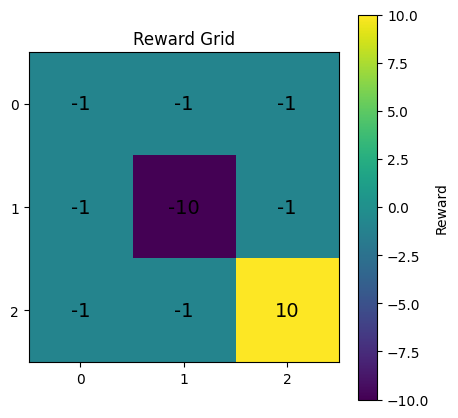

In [3]:
plt.figure(figsize=(5, 5))
plt.imshow(rewards)
plt.colorbar(label="Reward")
plt.title("Reward Grid")

for i in range(grid_size):
    for j in range(grid_size):
        plt.text(j, i, rewards[i, j], ha='center', va='center', fontsize=14)

plt.xticks(range(grid_size))
plt.yticks(range(grid_size))
plt.show()

# 8. Initialize Value Function

The **value function** tells us how good each state is.

At the start, we do not know the value of any state, so we initialize all values with zero.

In [15]:
V = np.zeros((grid_size, grid_size))

print("Initial Value Function:")
print(V)

Initial Value Function:
[[0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]]


# 9. Define Possible Actions

The robot can move in four directions:

| Action | Movement |
|---|---|
| Up | `(-1, 0)` |
| Down | `(1, 0)` |
| Left | `(0, -1)` |
| Right | `(0, 1)` |

In [5]:
actions = {
    "U": (-1, 0),
    "D": (1, 0),
    "L": (0, -1),
    "R": (0, 1)
}

print("Available Actions:")
for action, movement in actions.items():
    print(action, movement)

Available Actions:
U (-1, 0)
D (1, 0)
L (0, -1)
R (0, 1)


# 10. Helper Function: Check Valid Move

The robot should not move outside the grid.

This function checks whether the next cell is valid or not.

In [6]:
def is_valid_state(row, col):
    return 0 <= row < grid_size and 0 <= col < grid_size

# 11. Value Iteration Algorithm

Value Iteration updates the value of each state using the best possible next action.

---

##  Case 1: Deterministic Environment

In a deterministic environment, each action leads to **one निश्चित (certain) next state**.

The formula is:

$$
V(s) = \max_a \left[ R(s') + \gamma V(s') \right]
$$

Where:

- `V(s)` is the value of current state  
- `R(s')` is the reward of next state  
- `γ` is the discount factor  
- `V(s')` is the value of next state  

Here, we **do NOT multiply by probability** because the next state is certain.

---

##  Case 2: Stochastic Environment

In a stochastic environment, an action can lead to **multiple possible next states with different probabilities**.

The formula becomes:

$$
V(s) = \max_a \sum_{s'} P(s' \mid s, a)\left[ R(s') + \gamma V(s') \right]
$$

Where:

- `P(s' | s, a)` is the probability of reaching state `s'` from state `s` using action `a`  
 Here, we **multiply by probability** because outcomes are uncertain.

---


## Important Note

We multiply by probability **only when transitions are stochastic**.  
In deterministic environments, it is **not required**.

---

## Summary

Deterministic = single outcome → no probability  
Stochastic = multiple outcomes → use probability

In [7]:
def value_iteration(V, rewards, gamma, iterations=20):
    for iteration in range(iterations):
        new_V = np.copy(V)

        for i in range(grid_size):
            for j in range(grid_size):
                possible_values = []

                for action_name, action in actions.items():
                    ni = i + action[0]
                    nj = j + action[1]

                    if is_valid_state(ni, nj):
                        value = rewards[ni, nj] + gamma * V[ni, nj]
                        possible_values.append(value)

                if possible_values:
                    new_V[i, j] = max(possible_values)

        V = new_V

    return V

# 12. Run Value Iteration

Now we run the algorithm and print the final value function.

In [8]:
V = np.zeros((grid_size, grid_size))
V = value_iteration(V, rewards, gamma, iterations=20)

print("Final Value Function after Value Iteration:")
print(np.round(V, 2))

Final Value Function after Value Iteration:
[[27.09 31.07 36.99]
 [31.07 36.99 42.07]
 [36.99 42.07 36.99]]


# 13. Visualize the Value Function

Higher values mean better states.

The states closer to the goal should usually have higher values.

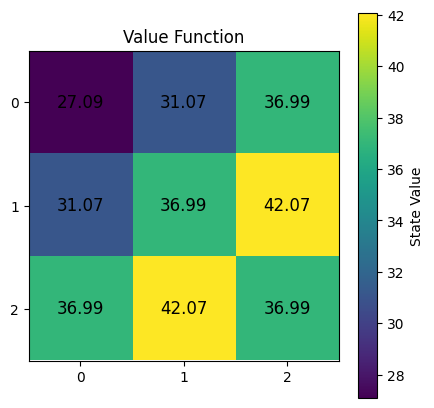

In [9]:
plt.figure(figsize=(5, 5))
plt.imshow(V)
plt.colorbar(label="State Value")
plt.title("Value Function")

for i in range(grid_size):
    for j in range(grid_size):
        plt.text(j, i, round(V[i, j], 2), ha='center', va='center', fontsize=12)

plt.xticks(range(grid_size))
plt.yticks(range(grid_size))
plt.show()

# 14. Policy Extraction

A **policy** tells the agent which action to take in each state.

For each cell, we check the neighboring cells and choose the direction that leads to the highest value.

In [10]:
def get_policy(V):
    policy = np.empty((grid_size, grid_size), dtype='<U2')

    for i in range(grid_size):
        for j in range(grid_size):
            best_value = -float('inf')
            best_action = ''

            for action_name, action in actions.items():
                ni = i + action[0]
                nj = j + action[1]

                if is_valid_state(ni, nj):
                    if V[ni, nj] > best_value:
                        best_value = V[ni, nj]
                        best_action = action_name

            policy[i, j] = best_action

    return policy

policy = get_policy(V)

print("Extracted Policy:")
print(policy)

Extracted Policy:
[['D' 'D' 'D']
 ['D' 'D' 'U']
 ['R' 'U' 'U']]


# 15. Visualize Policy with Arrows

We will convert policy letters into arrows:

| Letter | Meaning |
|---|---|
| U | ↑ |
| D | ↓ |
| L | ← |
| R | → |

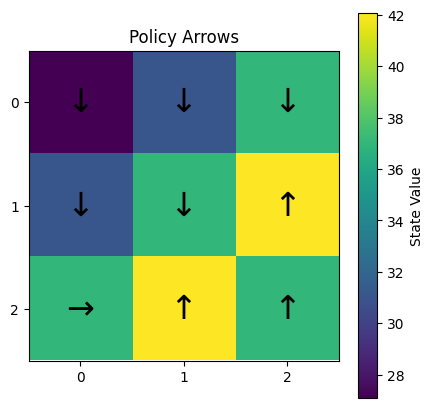

In [11]:
arrow_map = {
    "U": "↑",
    "D": "↓",
    "L": "←",
    "R": "→"
}

plt.figure(figsize=(5, 5))
plt.imshow(V)
plt.colorbar(label="State Value")
plt.title("Policy Arrows")

for i in range(grid_size):
    for j in range(grid_size):
        arrow = arrow_map.get(policy[i, j], "")
        plt.text(j, i, arrow, ha='center', va='center', fontsize=24)

plt.xticks(range(grid_size))
plt.yticks(range(grid_size))
plt.show()

# 16. Manual Exercise for Students

Answer the following manually:

### Question
At state `(0,0)`, which action is best and why?

### Hint
Check the values of possible next states:

- Down: `(1,0)`
- Right: `(0,1)`

Choose the action that leads to the state with higher value.

In [12]:
current_state = (0, 0)
print("Current State:", current_state)

for action_name, action in actions.items():
    ni = current_state[0] + action[0]
    nj = current_state[1] + action[1]

    if is_valid_state(ni, nj):
        print(f"Action {action_name} leads to state ({ni},{nj}) with value {round(V[ni, nj], 2)}")

Current State: (0, 0)
Action D leads to state (1,0) with value 31.07
Action R leads to state (0,1) with value 31.07


# 17. Experiment 1: Change Discount Factor

Now try different values of γ.

### Task
Run the code for:

- `γ = 0.5`
- `γ = 0.99`

Observe how the value function changes.

### Question
What happens when γ is closer to 1?

In [13]:
for gamma_test in [0.5, 0.99]:
    V_test = np.zeros((grid_size, grid_size))
    V_test = value_iteration(V_test, rewards, gamma_test, iterations=20)

    print(f"\nValue Function for gamma = {gamma_test}")
    print(np.round(V_test, 2))


Value Function for gamma = 0.5
[[-0.17  1.67  5.33]
 [ 1.67  5.33 12.67]
 [ 5.33 12.67  5.33]]

Value Function for gamma = 0.99
[[70.55 71.45 81.44]
 [71.45 81.44 82.45]
 [81.44 82.45 81.44]]


# 18. Experiment 2: Add Another Trap

Students can modify the reward grid by adding another trap.

For example, make cell `(0,2)` a trap with reward `-10`.

In [14]:
rewards_modified = np.array([
    [-1,  -1, -10],
    [-1, -10,  -1],
    [-1,  -1,  10]
])

V_modified = np.zeros((grid_size, grid_size))
V_modified = value_iteration(V_modified, rewards_modified, gamma=0.9, iterations=20)

print("Modified Reward Grid:")
print(rewards_modified)

print("\nValue Function after Adding Another Trap:")
print(np.round(V_modified, 2))

Modified Reward Grid:
[[ -1  -1 -10]
 [ -1 -10  -1]
 [ -1  -1  10]]

Value Function after Adding Another Trap:
[[27.09 22.16 36.99]
 [31.07 36.99 42.07]
 [36.99 42.07 36.99]]


# 19. Student Lab Tasks

## Task 1
Explain the following MDP components using your own example:

- State
- Action
- Reward
- Transition
- Discount factor

## Task 2
Modify the grid world:

- Change the goal position
- Add another trap
- Run value iteration again

## Task 3
Change the discount factor:

- Try `γ = 0.5`
- Try `γ = 0.9`
- Try `γ = 0.99`

Write the difference you observe.

## Task 4
Increase the grid size to `5x5`.

Add:

- One goal
- Two traps
- Normal cells

Then run value iteration.

## Task 1 — MDP Components Explained

An MDP is defined as **(S, A, P, R, γ)**. Each component explained using the 3×3 Grid World:

| Component | Meaning | Grid World Example |
|-----------|---------|-------------------|
| **S — State** | Current situation of the agent | Robot position: `(0,0)`, `(1,1)`, `(2,2)` |
| **A — Action** | What the agent can do | Up `(-1,0)`, Down `(1,0)`, Left `(0,-1)`, Right `(0,1)` |
| **R — Reward** | Feedback from environment | Goal = +10, Trap = −10, Normal = −1 |
| **P — Transition** | Probability of next state | Deterministic: robot moves exactly as chosen |
| **γ — Discount** | Importance of future rewards | γ=0.5 → short-sighted, γ=0.99 → far-sighted |

**Bellman Equations:**

Deterministic: $V(s) = \max_a \left[ R(s') + \gamma V(s') \right]$

Stochastic: $V(s) = \max_a \sum_{s'} P(s'|s,a) \left[ R(s') + \gamma V(s') \right]$

---

In [2]:
import numpy as np

grid_size = 3
gamma = 0.9
actions = {"U": (-1,0), "D": (1,0), "L": (0,-1), "R": (0,1)}

def is_valid(r, c):
    return 0 <= r < grid_size and 0 <= c < grid_size

def value_iteration(rewards, gamma, iterations=100):
    V = np.zeros((grid_size, grid_size))
    for _ in range(iterations):
        new_V = V.copy()
        for i in range(grid_size):
            for j in range(grid_size):
                vals = []
                for dr, dc in actions.values():
                    ni, nj = i+dr, j+dc
                    if is_valid(ni, nj):
                        vals.append(rewards[ni][nj] + gamma * V[ni][nj])
                if vals:
                    new_V[i][j] = max(vals)
        V = new_V
    return V

def get_policy(V):
    arrow = {"U":"↑","D":"↓","L":"←","R":"→"}
    policy = np.empty((grid_size, grid_size), dtype='<U2')
    for i in range(grid_size):
        for j in range(grid_size):
            best_val, best_a = -float('inf'), ''
            for a_name, (dr, dc) in actions.items():
                ni, nj = i+dr, j+dc
                if is_valid(ni, nj) and V[ni][nj] > best_val:
                    best_val = V[ni][nj]
                    best_a = a_name
            policy[i][j] = arrow[best_a]
    return policy

# Goal moved to (0,2), new trap at (2,0), original trap at (1,1)
rewards_t2 = np.array([
    [ -1,  -1,  10],
    [ -1, -10,  -1],
    [-10,  -1,  -1]
])

V2 = value_iteration(rewards_t2, gamma=0.9)
print("Value Function:\n", np.round(V2, 2))
print("Policy:\n", get_policy(V2))

Value Function:
 [[42.1  47.89 42.1 ]
 [36.89 42.1  47.89]
 [32.2  36.89 42.1 ]]
Policy:
 [['→' '↓' '↓']
 ['↑' '↑' '↑']
 ['↑' '↑' '↑']]


In [3]:
base_rewards = np.array([
    [ -1,  -1,  -1],
    [ -1, -10,  -1],
    [ -1,  -1,  10]
])

for g in [0.5, 0.9, 0.99]:
    V = value_iteration(base_rewards, gamma=g)
    print(f"\nγ = {g}")
    print("Values:\n", np.round(V, 2))
    print("Policy:\n", get_policy(V))


γ = 0.5
Values:
 [[-0.17  1.67  5.33]
 [ 1.67  5.33 12.67]
 [ 5.33 12.67  5.33]]
Policy:
 [['↓' '↓' '↓']
 ['↓' '↓' '↑']
 ['→' '↑' '↑']]

γ = 0.9
Values:
 [[32.2  36.89 42.1 ]
 [36.89 42.1  47.89]
 [42.1  47.89 42.1 ]]
Policy:
 [['↓' '↓' '↓']
 ['↓' '↓' '↑']
 ['→' '↑' '↑']]

γ = 0.99
Values:
 [[272.64 276.04 283.53]
 [276.04 283.53 287.04]
 [283.53 287.04 283.53]]
Policy:
 [['↓' '↓' '↓']
 ['↓' '↓' '↑']
 ['→' '↑' '↑']]


In [4]:
grid_size = 5

def is_valid(r, c):
    return 0 <= r < grid_size and 0 <= c < grid_size

def value_iteration_5x5(rewards, gamma, iterations=100):
    V = np.zeros((grid_size, grid_size))
    for _ in range(iterations):
        new_V = V.copy()
        for i in range(grid_size):
            for j in range(grid_size):
                vals = []
                for dr, dc in actions.values():
                    ni, nj = i+dr, j+dc
                    if is_valid(ni, nj):
                        vals.append(rewards[ni][nj] + gamma * V[ni][nj])
                if vals:
                    new_V[i][j] = max(vals)
        V = new_V
    return V

def get_policy_5x5(V):
    arrow = {"U":"↑","D":"↓","L":"←","R":"→"}
    policy = np.empty((grid_size, grid_size), dtype='<U2')
    for i in range(grid_size):
        for j in range(grid_size):
            best_val, best_a = -float('inf'), ''
            for a_name, (dr, dc) in actions.items():
                ni, nj = i+dr, j+dc
                if is_valid(ni, nj) and V[ni][nj] > best_val:
                    best_val = V[ni][nj]
                    best_a = a_name
            policy[i][j] = arrow[best_a]
    return policy

# 5x5: Goal at (4,4), Trap 1 at (1,2), Trap 2 at (3,1)
rewards_5x5 = np.full((5, 5), -1)
rewards_5x5[4][4] =  10   # Goal
rewards_5x5[1][2] = -10   # Trap 1
rewards_5x5[3][1] = -10   # Trap 2

V5 = value_iteration_5x5(rewards_5x5, gamma=0.9)
print("Reward Grid:\n", rewards_5x5)
print("\nValue Function:\n", np.round(V5, 2))
print("\nPolicy:\n", get_policy_5x5(V5))

Reward Grid:
 [[ -1  -1  -1  -1  -1]
 [ -1  -1 -10  -1  -1]
 [ -1  -1  -1  -1  -1]
 [ -1 -10  -1  -1  -1]
 [ -1  -1  -1  -1  10]]

Value Function:
 [[17.69 20.77 24.19 27.98 32.2 ]
 [20.77 24.19 27.98 32.2  36.89]
 [24.19 27.98 32.2  36.89 42.1 ]
 [27.98 32.2  36.89 42.1  47.89]
 [32.2  36.89 42.1  47.89 42.1 ]]

Policy:
 [['↓' '↓' '↓' '↓' '↓']
 ['↓' '↓' '↓' '↓' '↓']
 ['↓' '↓' '↓' '↓' '↓']
 ['↓' '↓' '↓' '↓' '↑']
 ['→' '→' '→' '↑' '↑']]


# 20. Key Takeaways

- MDP is used to model decision-making problems.
- The agent interacts with the environment using states and actions.
- Rewards guide the agent toward better behavior.
- The discount factor controls the importance of future rewards.
- Value Iteration helps compute how good each state is.
- A policy tells the agent which action to take in each state.

---

## One-Line Definition

**MDP is a decision-making model where an agent chooses actions in states to maximize rewards over time.**